Importing dependancies

In [9]:
import time
import numpy as np, pandas as pd, geopandas as gpd, requests
from shapely.geometry import box
from scipy.spatial import cKDTree
import numpy as np, pandas as pd, geopandas as gpd
import os, time, requests, pandas as pd
from collections import deque
from datetime import date, timedelta
import glob, os
import pandas as pd, geopandas as gpd
from shapely import MultiPoint

The Ecmwf_ifs model works on 9km² grid, and we can't recieve that grid, so we will try to make our own grid and check how close it is to the real locations.

In [13]:
url = "https://archive-api.open-meteo.com/v1/archive"
dlat, dlon = 0.08, 0.12  #roughly 9 km at 52°N

# First we get a grid of cell centers, clipped to the Netherlands
lats = np.round(np.arange(50.70, 53.70, dlat), 3)
lons = np.round(np.arange(3.20, 7.40, dlon), 3)
grid = gpd.GeoDataFrame( [(la, lo) for la in lats for lo in lons], columns = ["lat", "lon"])
grid["geometry"] = [box(lo - dlon/2, la - dlat/2, lo + dlon/2, la + dlat/2)
                    for la, lo in zip(grid.lat, grid.lon)]
grid = grid.set_crs(4326)
nl = gpd.read_file("nl.json").to_crs(4326)
grid = grid[grid.intersects(nl.union_all())].reset_index(drop=True)
print(len(grid), "grid cells that intersects the Netherlands")

#Ask the API which model cell each centre falls in
def discover(batch, day, retries = 3):
    params = {
        "latitude": ",".join(f"{x:.3f}" for x in batch["lat"]),
        "longitude": ",".join(f"{x:.3f}" for x in batch["lon"]),
        "start_date": day, "end_date": day,
        "daily": "precipitation_sum", "models": "ecmwf_ifs",
        "timezone": "Europe/Amsterdam",
    }
    for attempt in range(retries):
        r = requests.get(url, params = params, timeout = 60)
        if r.status_code == 429:
            time.sleep(60 * (attempt + 1))
            continue
        r.raise_for_status()
        data = r.json()
        return [data] if isinstance (data, dict) else data
    raise RuntimeError("Still rate limited")

rows = []
amount = 50
for i in range(0, len(grid), amount):
    batch = grid.iloc[i:i + amount]
    answers = discover(batch, "2025-06-01")
    for (_, p), location in zip(batch.iterrows(), answers):
        rows.append((p.lat, p.lon, location["latitude"], location["longitude"]))
    time.sleep(1)
    print(f"{min(i + 50, len(grid))}/ {len(grid)} done")

# Measure the offset between my points and the model cell it hit
chk = pd.DataFrame(rows, columns = ["lat", "lon", "cell_lat", "cell_lon"]).round(4)
chk["offset_km"] = np.hypot((chk.cell_lat - chk.lat) * 111,
                          (chk.cell_lon - chk.lon) * 111 * np.cos(np.radians(chk.lat)))

print(chk["offset_km"].describe().round(1))
n_cells = chk[["cell_lat", "cell_lon"]].drop_duplicates().shape[0]
print(len(chk), "grid points ->", n_cells, "distinct model cells")
chk.to_parquet("ifs_grid_check.parquet")

C:\Users\Zakaria\AppData\Local\Temp\ipykernel_6656\2401582252.py:8: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  grid["geometry"] = [box(lo - dlon/2, la - dlat/2, lo + dlon/2, la + dlat/2)


629 grid cells that intersects the Netherlands
50/ 629 done
100/ 629 done
150/ 629 done
200/ 629 done
250/ 629 done
300/ 629 done
350/ 629 done
400/ 629 done
450/ 629 done
500/ 629 done
550/ 629 done
600/ 629 done
629/ 629 done
count    629.0
mean       4.3
std        2.5
min        0.1
25%        2.7
50%        4.0
75%        5.2
max       19.8
Name: offset_km, dtype: float64
629 grid points -> 438 distinct model cells


Checking which grid points have a large offset with the model's grid

37 points with offset > 8 km


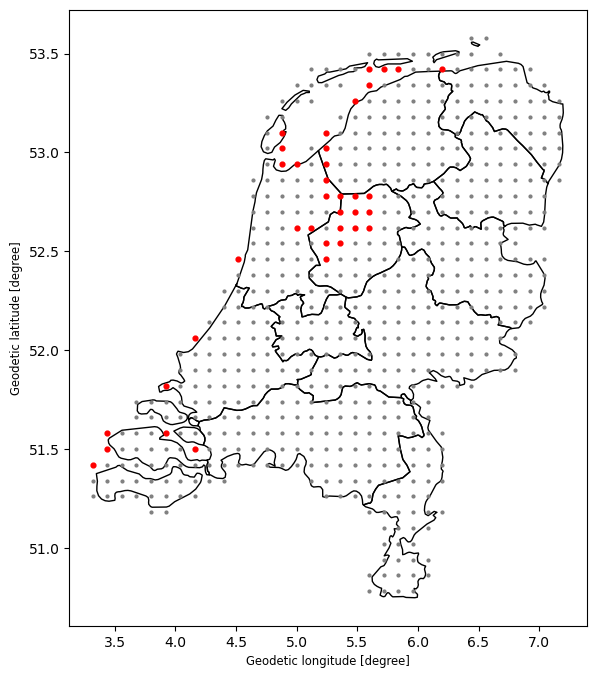

In [16]:
big = chk[chk.offset_km > 8].sort_values("offset_km", ascending = False)
print(len(big), "points with offset > 8 km")
big.head(10)

ax = nl.plot(color = "none", edgecolor = "black", figsize = (7,8))
ax.scatter (chk.lon, chk.lat, s = 4, c = "grey")
ax.scatter (big.lon, big.lat, s=12, c = "red")

The grid points with large offset are the ones on bodies of water

Checking how far the points of the new grid made from the model

In [4]:
chk = pd.read_parquet("ifs_grid_check.parquet")
cen = chk[["cell_lat", "cell_lon"]].drop_duplicates().reset_index(drop=True)
g = gpd.GeoDataFrame(cen, geometry=gpd.points_from_xy(cen.cell_lon, cen.cell_lat),
                     crs=4326).to_crs(28992)
xy = np.column_stack([g.geometry.x, g.geometry.y])
d, _ = cKDTree(xy).query(xy, k=2)
print((pd.Series(d[:, 1]) / 1000).describe().round(1))

count    438.0
mean       8.0
std        0.6
min        7.8
25%        7.8
50%        7.9
75%        7.9
max       15.7
dtype: float64


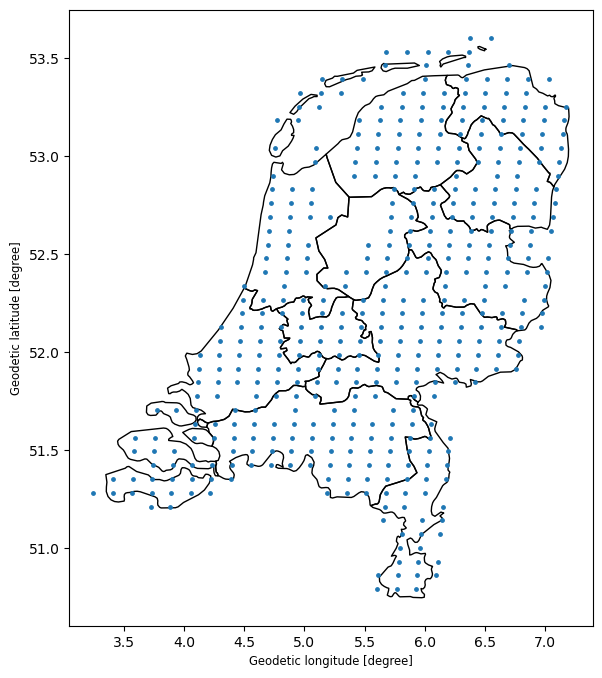

In [6]:
nl = gpd.read_file("nl.json").to_crs(4326)
ax = nl.plot(color="none", edgecolor="black", figsize=(7, 8))
ax.scatter(cen.cell_lon, cen.cell_lat, s=6)

Everything looks good, so we save the grid points

In [7]:
cells = (cen[["cell_lat", "cell_lon"]].drop_duplicates()
           .rename(columns={"cell_lat": "lat", "cell_lon": "lon"})
           .reset_index(drop=True))
cells["cell_id"] = cells.index
cells.to_parquet("ifs_cells.parquet")

We test our ECMWF IFS precipitation data pipeline

In [13]:
url = "https://archive-api.open-meteo.com/v1/archive"
def fetch_cells(batch, start, end, retries = 3):
    params = {
        "latitude": ",".join(f"{x:.4f}" for x in batch["lat"]),
        "longitude": ",".join(f"{x:.4f}" for x in batch["lon"]),
        "start_date": start, "end_date": end,
        "daily": "precipitation_sum", "models": "ecmwf_ifs",
        "timezone": "Europe/Amsterdam",
    }
    for attempt in range(retries):
        r = requests.get(url, params = params, timeout= 120)
        if r.status_code == 429:
            time.sleep(60)
            continue
        r.raise_for_status()
        data = r.json()
        return [data] if isinstance (data, dict) else data
    raise RunTimeError("Still rate limited")

test = cells.iloc[:10] #We test the first 10 rows
t0 = time.time()  #Record the start time
answers = fetch_cells(test, "2025-01-01", "2025-12-31")
print(f"{time.time() - t0:.1f} s")

parts, mismatches = [], 0
for (_, c), location in zip (test.iterrows(), answers):
    if abs(location['latitude'] - c.lat) > 0.001 or abs(location["longitude"] - c.lon) > 0.001:
        mismatches += 1
    parts.append(pd.DataFrame({
        "date": pd.to_datetime(location["daily"]["time"]),
        "rain_mm": location["daily"]["precipitation_sum"],
        "cell_id": c.cell_id, }))
    
df = pd.concat(parts, ignore_index = True)
print(len(df), "rows(expect 3650)")
print("nulls", df.rain_mm.isna().sum(), "| cell mismatches", mismatches)
print(df.groupby("cell_id").rain_mm.sum().round(0).describe())

0.1 s
3650 rows(expect 3650)
nulls 0 | cell mismatches 0
count     10.000000
mean     728.100000
std       23.244832
min      691.000000
25%      712.750000
50%      731.000000
75%      743.750000
max      763.000000
Name: rain_mm, dtype: float64


The results are great; let's download historical data
Since we have a large grid we will download the data in chunks to avoide reaching API rate limits

In [ ]:
cells = pd.read_parquet("ifs_cells.parquet")
url = "https://archive-api.open-meteo.com/v1/archive"
out = "ifs_raw"
os.makedirs(out, exist_ok = True) #make folder

batch_size = 10
years = [2025, 2024, 2023] 

def fetch_batch(batch, start, end):
    params = {
        "latitude": ",".join(f"{x:.4f}" for x in batch["lat"]),
        "longitude": ",".join(f"{x:.4f}" for x in batch["lon"]),
        "start_date": start, "end_date": end,
        "daily": "precipitation_sum", "models": "ecmwf_ifs",
        "timezone": "Europe/Amsterdam",
    }
    for attempt in range(5):
        r = requests.get(url, params=params, timeout=120)
        if r.status_code == 429:
            reason = r.json().get("reason", "")
            print("Rate limited:", reason)
            if "daily" in reason.lower():
                return None                        # out of budget for today
            time.sleep(60)                         # minute/hour limit: wait, retry
            continue
        r.raise_for_status()
        data = r.json()
        return [data] if isinstance(data, dict) else data
    return None                                    # still limited: stop the run

def todo():
    jobs = []
    for year in years:
        end = min(date(year,12,31), date.today() - timedelta(days = 5))
        start = date(year,1, 1)
        for b in range(0, len(cells), batch_size):
            path =  f"{OUT}/{year}_{b // batch_size:03d}.parquet"
            if not os.path.exists(path):
                jobs.append((year, b, start, end, path))
        return jobs

def run():
    jobs = todo()
    print(f"{len(jobs)} chunks left")
    for year, b, start, end, path, in jobs:
        batch = cells.iloc[b:b + batch_size]
        answers = fetch_batch(batch, start.isoformat(), end.isoformat())
        if answers is None:
            print("Stopping; run again later")
            return
        parts = []
        for (_, c), location in zip(batch.iterrows(), answers):
            if abs(location["latitude"] - c.lat) > 0.001 or abs(location["longitude"] - c.lon) > 0.001:
                print("WARNING: cell mismatch", c.cell_id)
        parts.append(pd.DataFrame({
                "date": pd.to_datetime(location["daily"]["time"]),
                "rain_mm": location["daily"]["precipitation_sum"],
                "cell_id": c.cell_id}))
        df = pd.concat(parts, ignore_index = True).dropna(subset = ["rain_mm"])
        df.to_parquet(path + ".tmp")
        os.replace(path + ".tmp", path)            
        print(f"{os.path.basename(path)} saved")
    print("All chunks done.")

run()

Creating Voronoi polygons for map visualization

In [12]:
import os, glob
import numpy as np, pandas as pd, geopandas as gpd, shapely
from shapely import MultiPoint

cells = pd.read_parquet("ifs_cells.parquet")
nl = gpd.read_file("nl.json").to_crs(28992)
nl_shape = nl.union_all()                      

pts = gpd.GeoDataFrame(cells,
            geometry=gpd.points_from_xy(cells.lon, cells.lat), crs=4326).to_crs(28992)
vor = shapely.voronoi_polygons(MultiPoint(pts.geometry.tolist()))
polys = gpd.GeoDataFrame(geometry=list(vor.geoms), crs=28992)
polys = gpd.sjoin(polys, pts, predicate="contains").drop(columns="index_right")

polys["geometry"] = polys.geometry.intersection(nl_shape)
polys = polys[~polys.is_empty].copy()
polys["geometry"] = polys.geometry.simplify(200)
polys = polys.to_crs(4326)
polys[["cell_id", "geometry"]].to_file("ifs_cell_polygons.geojson", driver="GeoJSON")
print(len(polys), "cell polygons saved (of", len(cells), "cells)")

429 cell polygons saved (of 438 cells)
